# 01 - Exploratory Data Analysis

Explore the raw UCI Diabetes 130-US Hospitals dataset: shape, missingness, target balance, and a couple of distributions relevant to readmission.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from src.data.load_data import load_raw_data

df = load_raw_data()
df.shape

(101766, 50)

## Missing values

The dataset encodes missingness as `"?"`, which `load_raw_data` already converts to `NaN`. A handful of columns are almost entirely missing.

In [2]:
missing_pct = df.isna().mean().sort_values(ascending=False)
missing_pct[missing_pct > 0]

weight               0.968585
max_glu_serum        0.947468
A1Cresult            0.832773
medical_specialty    0.490822
payer_code           0.395574
race                 0.022336
diag_3               0.013983
diag_2               0.003518
diag_1               0.000206
dtype: float64

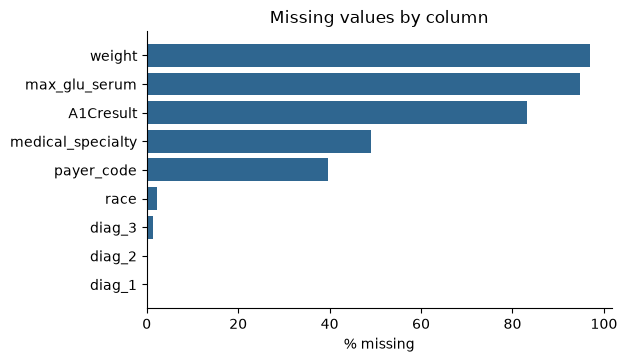

In [3]:
from src.visualization.visualize import plot_missingness

plot_missingness(df, save_as="01_missingness.png")

`weight`, `payer_code`, and `medical_specialty` are the standouts (>40% missing) — those get dropped in preprocessing rather than imputed.

## Target balance

The raw `readmitted` column has three levels. The project frames this as binary: readmitted within 30 days, or not.

In [4]:
df["readmitted"].value_counts(normalize=True)

readmitted
NO     0.539119
>30    0.349282
<30    0.111599
Name: proportion, dtype: float64

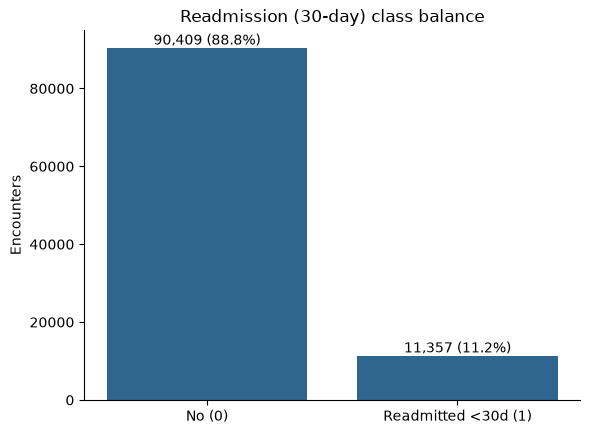

In [5]:
from src.data.clean_data import add_readmission_target
from src.visualization.visualize import plot_target_balance
from src.config import TARGET_COLUMN

df_target = add_readmission_target(df.copy())
plot_target_balance(df_target, TARGET_COLUMN, save_as="01_target_balance.png")

Only about 1 in 9 encounters is a <30-day readmission — this is an imbalanced classification problem, which shapes the modeling choices later (`class_weight="balanced"`, looking at recall/ROC-AUC rather than accuracy).

## Readmission rate vs. prior utilization

A quick look at whether patients with more prior inpatient stays are more likely to be readmitted within 30 days — a feature we'd expect to matter a lot.

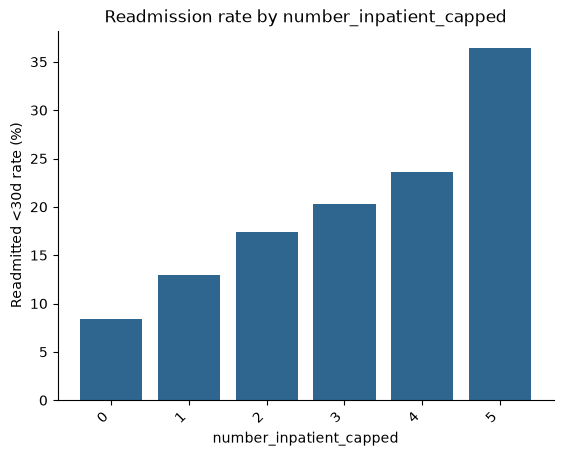

In [6]:
from src.visualization.visualize import plot_readmission_rate_by

df_target["number_inpatient_capped"] = df_target["number_inpatient"].clip(upper=5)
plot_readmission_rate_by(df_target, "number_inpatient_capped", TARGET_COLUMN, save_as="01_readmit_rate_by_prior_inpatient.png")

Readmission rate climbs sharply with the number of prior inpatient visits — patients with several previous admissions are readmitted far more often than first-time patients. This is a strong early signal that prior utilization counts will be important features.